In [165]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack
import csv
import pandas as pd

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
plt.rcParams['axes.grid'] = True

In [166]:
metal_trial_1_data = pd.read_csv('data/exp3_metal_trial1.gambl.csv')
metal_trial_2_data = pd.read_csv('data/exp3_metal_trial2.gambl.csv')
metal_trial_3_data = pd.read_csv('data/exp3_metal_trial3.gambl.csv')



In [167]:
temp_err = 0.5

water_heat_capacity = 4.184 # J g^-1 C^-1
cup_wall_thickness = 0.26
cup_wall_thickness_err = 0.02

cup_bottom_thickness = 0.24
cup_bottom_thickness_err = 0.02

cup_mass = 47
cup_mass_err = 1


water_mass = np.array([234, 187, 196]) - cup_mass
water_mass_err = np.sqrt(np.array([1, 1, 1])**2 + cup_mass_err**2)

top_radius = np.ones(3) * 35.24
top_radius_err = np.array([1, 1, 1])
bottom_radius = np.ones(3) * 35.24
bottom_radius_err = np.array([1, 1, 1])

bottom_surface_area = np.pi * bottom_radius**2 # mm^2
bottom_surface_area_err = np.pi * 2 * bottom_radius * bottom_radius_err

water_volume = water_mass * 1000
water_slant_height = water_volume / (np.pi * bottom_radius**2) - cup_bottom_thickness
water_slant_height_err = np.array([3, 3, 3])

print(water_slant_height)

side_surface_area = np.pi * (bottom_radius + top_radius) * water_slant_height # mm^2
side_surface_area_err = np.pi * np.sqrt(((bottom_radius + top_radius) * water_slant_height_err)**2 + (bottom_radius_err*water_slant_height)**2 + (top_radius_err*water_slant_height)**2)

# initial_temp = np.array([8.963, 42.727, 22.641])
# initial_temp_err = np.array([0.019, 0.034, 0.087])

bath_temp = np.array([46.828, 45.539, 43.624])
bath_temp_err = np.array([0.010, 0.012, 0.074])



#trial_2_start_idx = 0#np.argmin(np.abs(styrofoam_trial_2_data['Data Set 8:Time(s)'] - 90))
#trial_2_stop_idx = len(metal_trial_2_data['Data Set 8:Time(s)']) - 1#np.argmin(np.abs(styrofoam_trial_2_data['Data Set 8:Time(s)'] - 300))

metal_trial_times = np.array([
    metal_trial_1_data['Data Set 3:Time(s)'],
    metal_trial_2_data['Data Set 3:Time(s)'],#[trial_2_start_idx:trial_2_stop_idx] - metal_trial_2_data['Data Set 8:Time(s)'][trial_2_start_idx],
    metal_trial_3_data['Data Set 5:Time(s)']], dtype=pd.Series)



metal_trial_temps = np.array([
    metal_trial_1_data['Data Set 3:Temperature(°C)'],
    metal_trial_2_data['Data Set 3:Temperature(°C)'],#[trial_2_start_idx:trial_2_stop_idx],
    metal_trial_3_data['Data Set 5:Temperature(°C)']], dtype=pd.Series)


[47.69138015 35.64445573 37.95131359]


In [168]:

def linear_fit(t, beta, T0, T_bath):
    return -beta * (T0 - T_bath) * t + T0


def line(x, m):
    return m*x


def exponential_fit(t, beta, T0, T_bath):
    return (T0 - T_bath) * np.exp(-1 * beta * t) + T_bath




In [169]:
beta = np.ones(3)
T0 = np.ones(3)
beta_err = np.ones(3)
T0_err = np.ones(3)

for i in range(3):
    popt_lin, pcov_lin = scipy.optimize.curve_fit(lambda t, beta, T0: linear_fit(t, beta, T0, bath_temp[i]), metal_trial_times[i], metal_trial_temps[i], maxfev=10000, p0=(-1, 10))
    popt_exp, pcov_exp = scipy.optimize.curve_fit(lambda t, beta, T0: exponential_fit(t, beta, T0, bath_temp[i]), metal_trial_times[i], metal_trial_temps[i], p0=(popt_lin[0], popt_lin[1]), maxfev=10000)

    beta[i] = popt_exp[0]
    T0[i] = popt_exp[1]
    beta_err[i] = np.sqrt(pcov_exp[0][0])
    T0_err[i] = np.sqrt(pcov_exp[1][1])

# beta_lin = popt_lin[0]
# T0_lin = popt_lin[1]

# beta_lin_err = np.sqrt(pcov_lin[0][0])
# T0_lin_err = np.sqrt(pcov_lin[1][1])
#T_bath_lin = popt_lin[2]

#print(C_lin, T0_lin)





#Conductivity in W m^-1 K^-1
#K_lin = 1000 * beta_lin * ((cup_wall_thickness / side_surface_area + cup_bottom_thickness / bottom_surface_area) * water_mass * water_heat_capacity)[i]

K = beta * ((cup_wall_thickness / side_surface_area + cup_bottom_thickness / bottom_surface_area) * water_mass * water_heat_capacity)

K_err = np.sqrt((K**2 * ((water_mass_err / water_mass)**2 + (beta_err / beta)**2)) + ((water_mass * water_heat_capacity * beta)**2 * ((cup_wall_thickness_err / side_surface_area)**2 + (cup_bottom_thickness_err / bottom_surface_area)**2 + (side_surface_area_err * cup_wall_thickness / (side_surface_area**2))**2 + (bottom_surface_area_err * cup_bottom_thickness / (bottom_surface_area**2))**2)))

K *= 1000
K_err *= 1000

#print(1000*beta)
print(K)
print(K_err)

[0.37026089 0.30492265 0.32118409]
[0.02889537 0.02372444 0.02489429]


1.772446578040688
1.693486082253411
3.4240757424082635


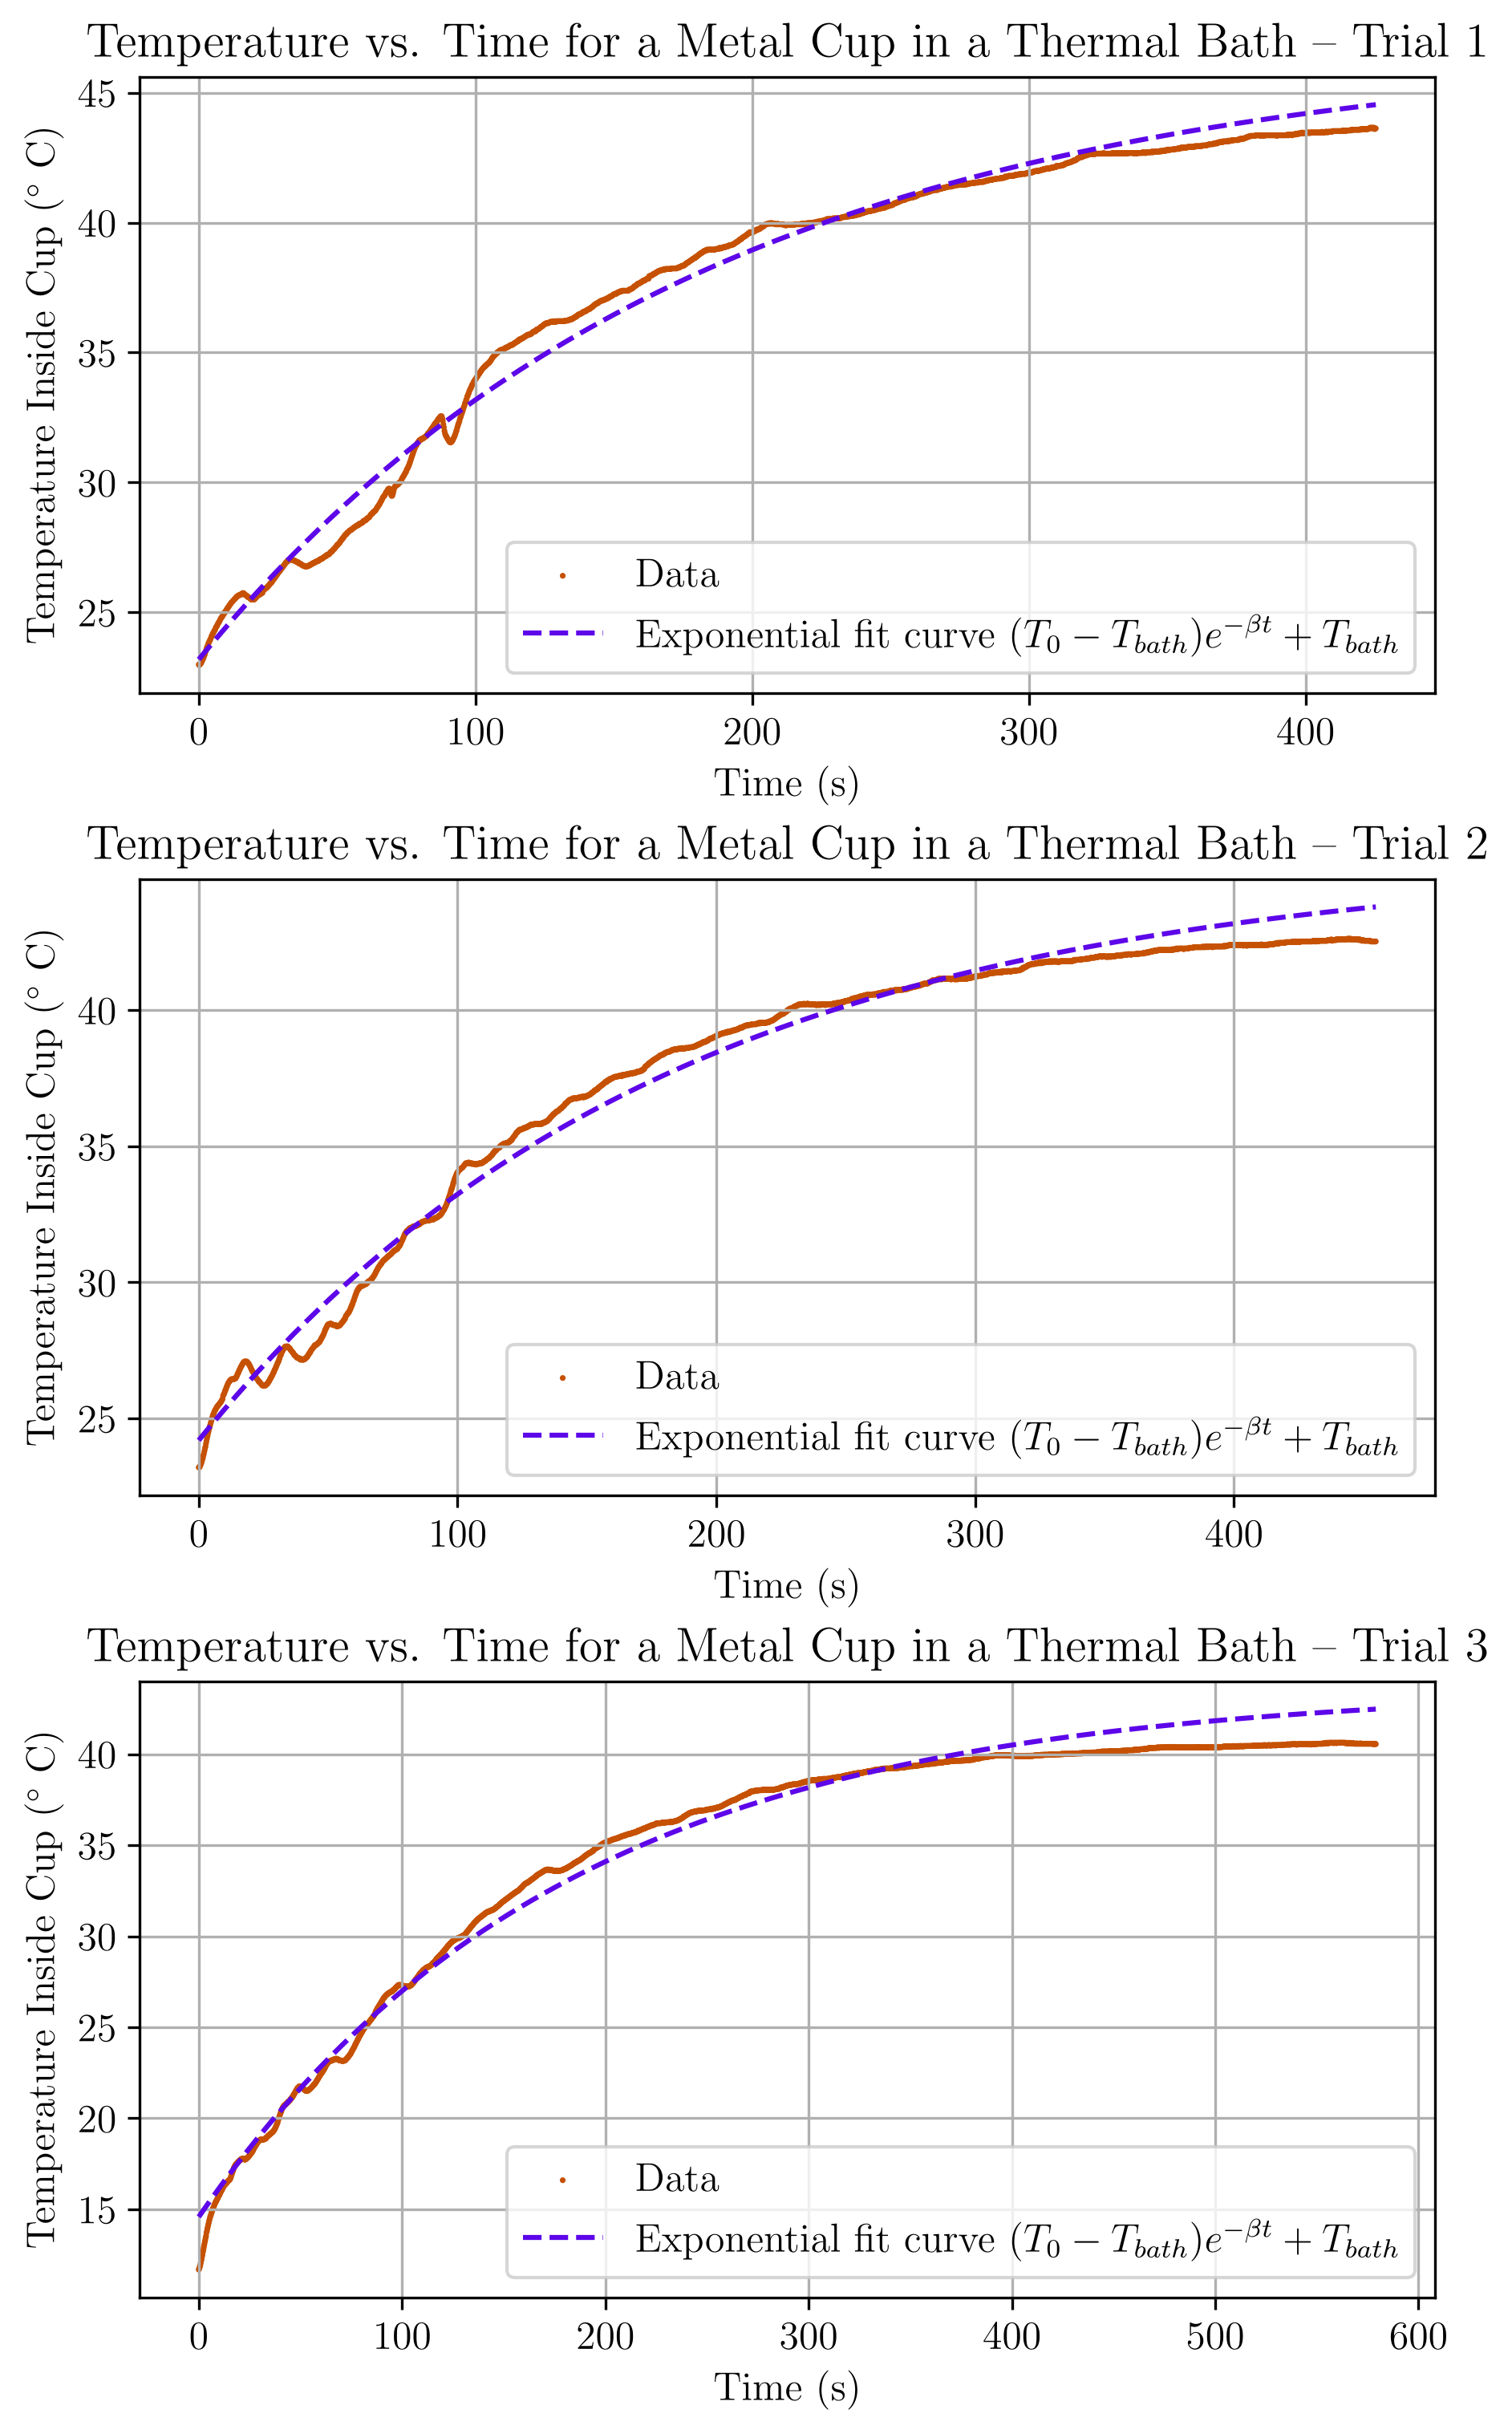

In [170]:


fig, axs = plt.subplots(3, figsize=(6, 10), layout='constrained')


for i, ax in enumerate(axs):
    ax.scatter(metal_trial_times[i], metal_trial_temps[i], edgecolors='none', s = 3, color = 'xkcd:dark orange', label = 'Data')

    x_vals = np.linspace(0, max(metal_trial_times[i]), 100)

    #ax.plot(x_vals, linear_fit(x_vals, C_lin, T0_lin), color = 'blueviolet')

    ax.plot(x_vals, exponential_fit(x_vals, beta[i], T0[i], bath_temp[i]), linestyle = 'dashed', color='xkcd:blue violet',
            label = rf"Exponential fit curve $(T_0 - T_{{bath}})e^{{-\beta t}} + T_{{bath}}$")


    ax.set_title(f"Temperature vs. Time for a Metal Cup in a Thermal Bath -- Trial {i+1}")
    ax.set_xlabel(r"Time (s)")
    ax.set_ylabel(r"Temperature Inside Cup ($^\circ$ C)")

    ax.legend()

    chi2 = np.sum((metal_trial_temps[i] - exponential_fit(metal_trial_times[i], beta[i], T0[i], bath_temp[i]))**2 / temp_err**2)
    reduced_chi2 = chi2 / (len(metal_trial_temps[i]) - 2)

    print(reduced_chi2)

    fig.savefig("plots/metal_temp_vs_time.png", dpi=400)

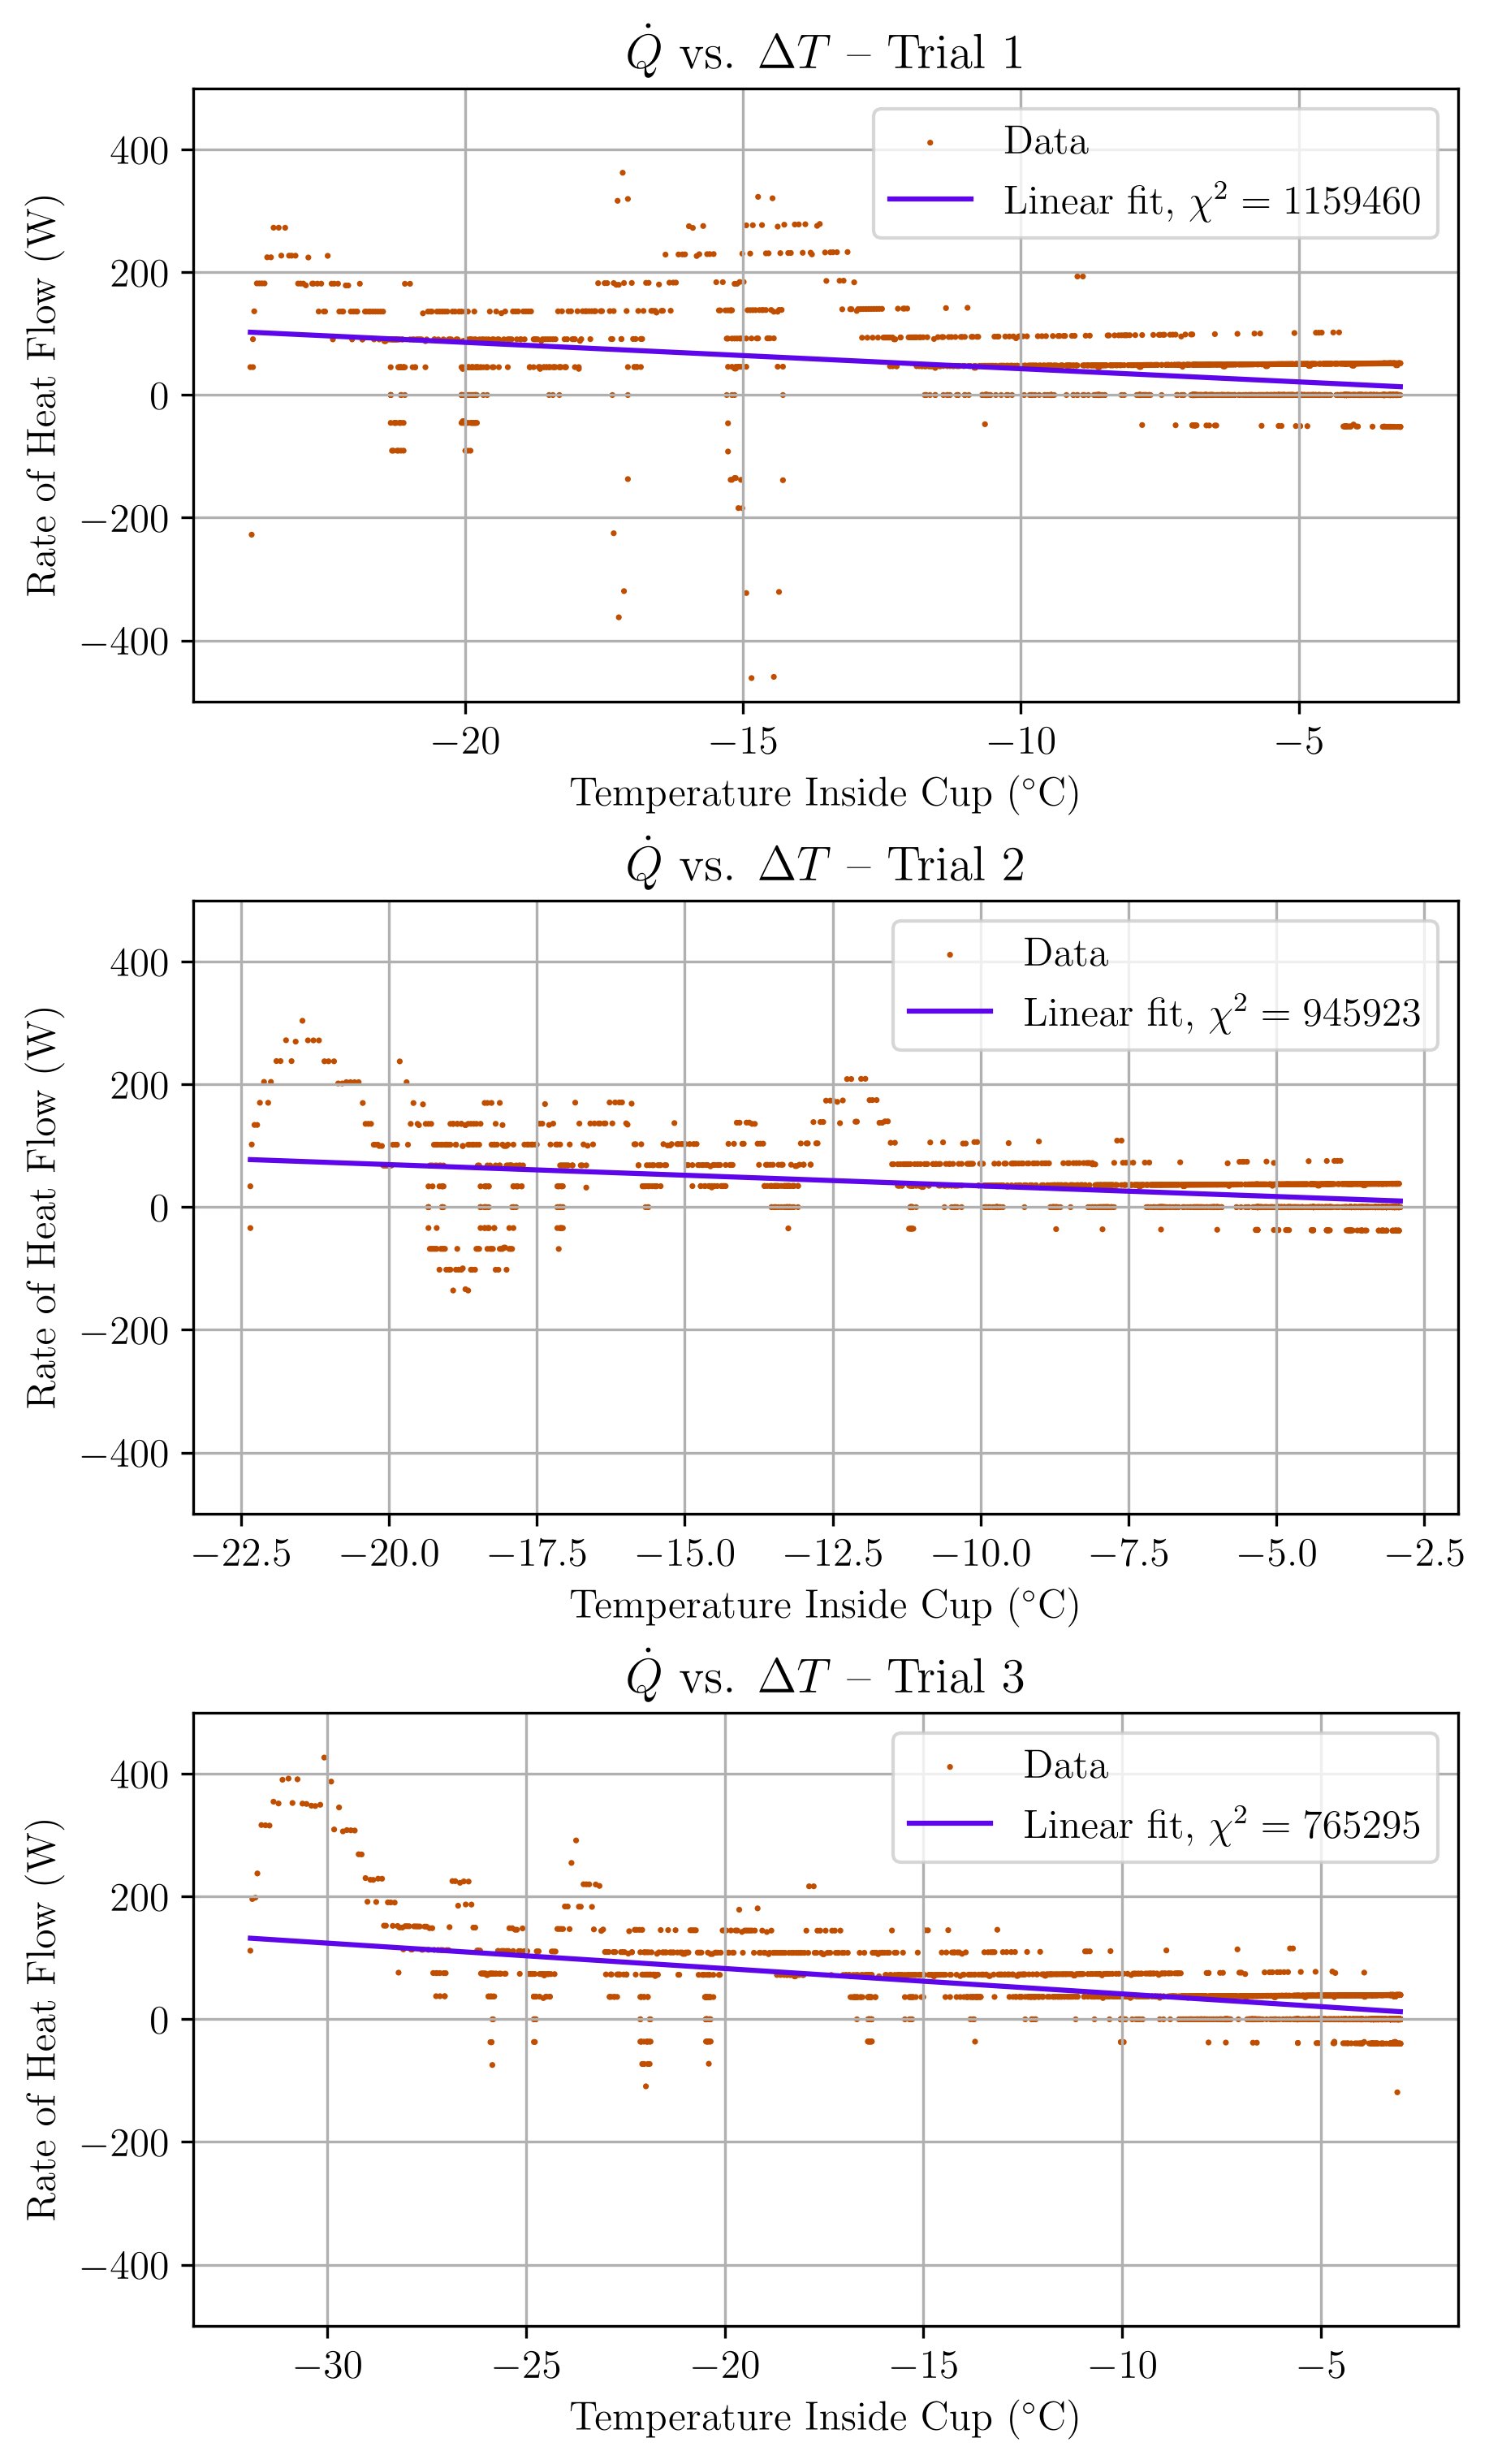

In [ ]:
roc_fig, roc_axs = plt.subplots(3, figsize=(6, 10), layout='constrained')

colors = ['xkcd:burnt orange', 'xkcd:burnt orange', 'xkcd:burnt orange']


for i, ax in enumerate(roc_axs):
    beta[i] = popt_exp[0]
    T0[i] = popt_exp[1]
    beta_err[i] = np.sqrt(pcov_exp[0][0])
    T0_err[i] = np.sqrt(pcov_exp[1][1])
    
    T_dot = np.gradient(metal_trial_temps[i], metal_trial_times[i], edge_order=2)
    Q_dot = T_dot * water_mass[i] * water_heat_capacity

    Q_dot_err = Q_dot * np.sqrt((water_mass_err[i] / water_mass[i])**2)

    deltaT = metal_trial_temps[i] - bath_temp[i]

    popt, pcov = scipy.optimize.curve_fit(line, deltaT, Q_dot, maxfev=10000)

    slope = popt[0]
    slope_err = np.sqrt(pcov[0][0])

    linear_chi2 = np.sum((Q_dot - line(deltaT, slope))**2 / (slope**2 * (temp_err**2 + bath_temp_err[i]**2) +  Q_dot_err**2))
    linear_reduced_chi2 = linear_chi2 / (len(deltaT) - 1)

    ax.scatter(deltaT, Q_dot, edgecolors='none', s = 3, color = colors[i], label = 'Data')

    x_vals = np.linspace(min(deltaT), max(deltaT), 100)

    ax.plot(x_vals, line(x_vals, slope), color='xkcd:blue violet', label = rf"Linear fit, $\chi^2 = {linear_chi2:0.0f}$")


    ax.set_title(rf"$\dot{{Q}}$ vs. $\Delta T$ -- Trial {i+1}")
    ax.set_xlabel(r"Temperature Difference ($^\circ$C)")
    ax.set_ylabel(r"Rate of Heat Flow (W)")

    ax.set_ylim(-500, 500)

    ax.legend()

roc_fig.savefig("plots/metal_heat_flow_vs_temp.png", dpi=400)

0.32769836313190065 0.014763496843707435
[0.37026089 0.30492265 0.32118409]
[0.02889537 0.02372444 0.02489429]


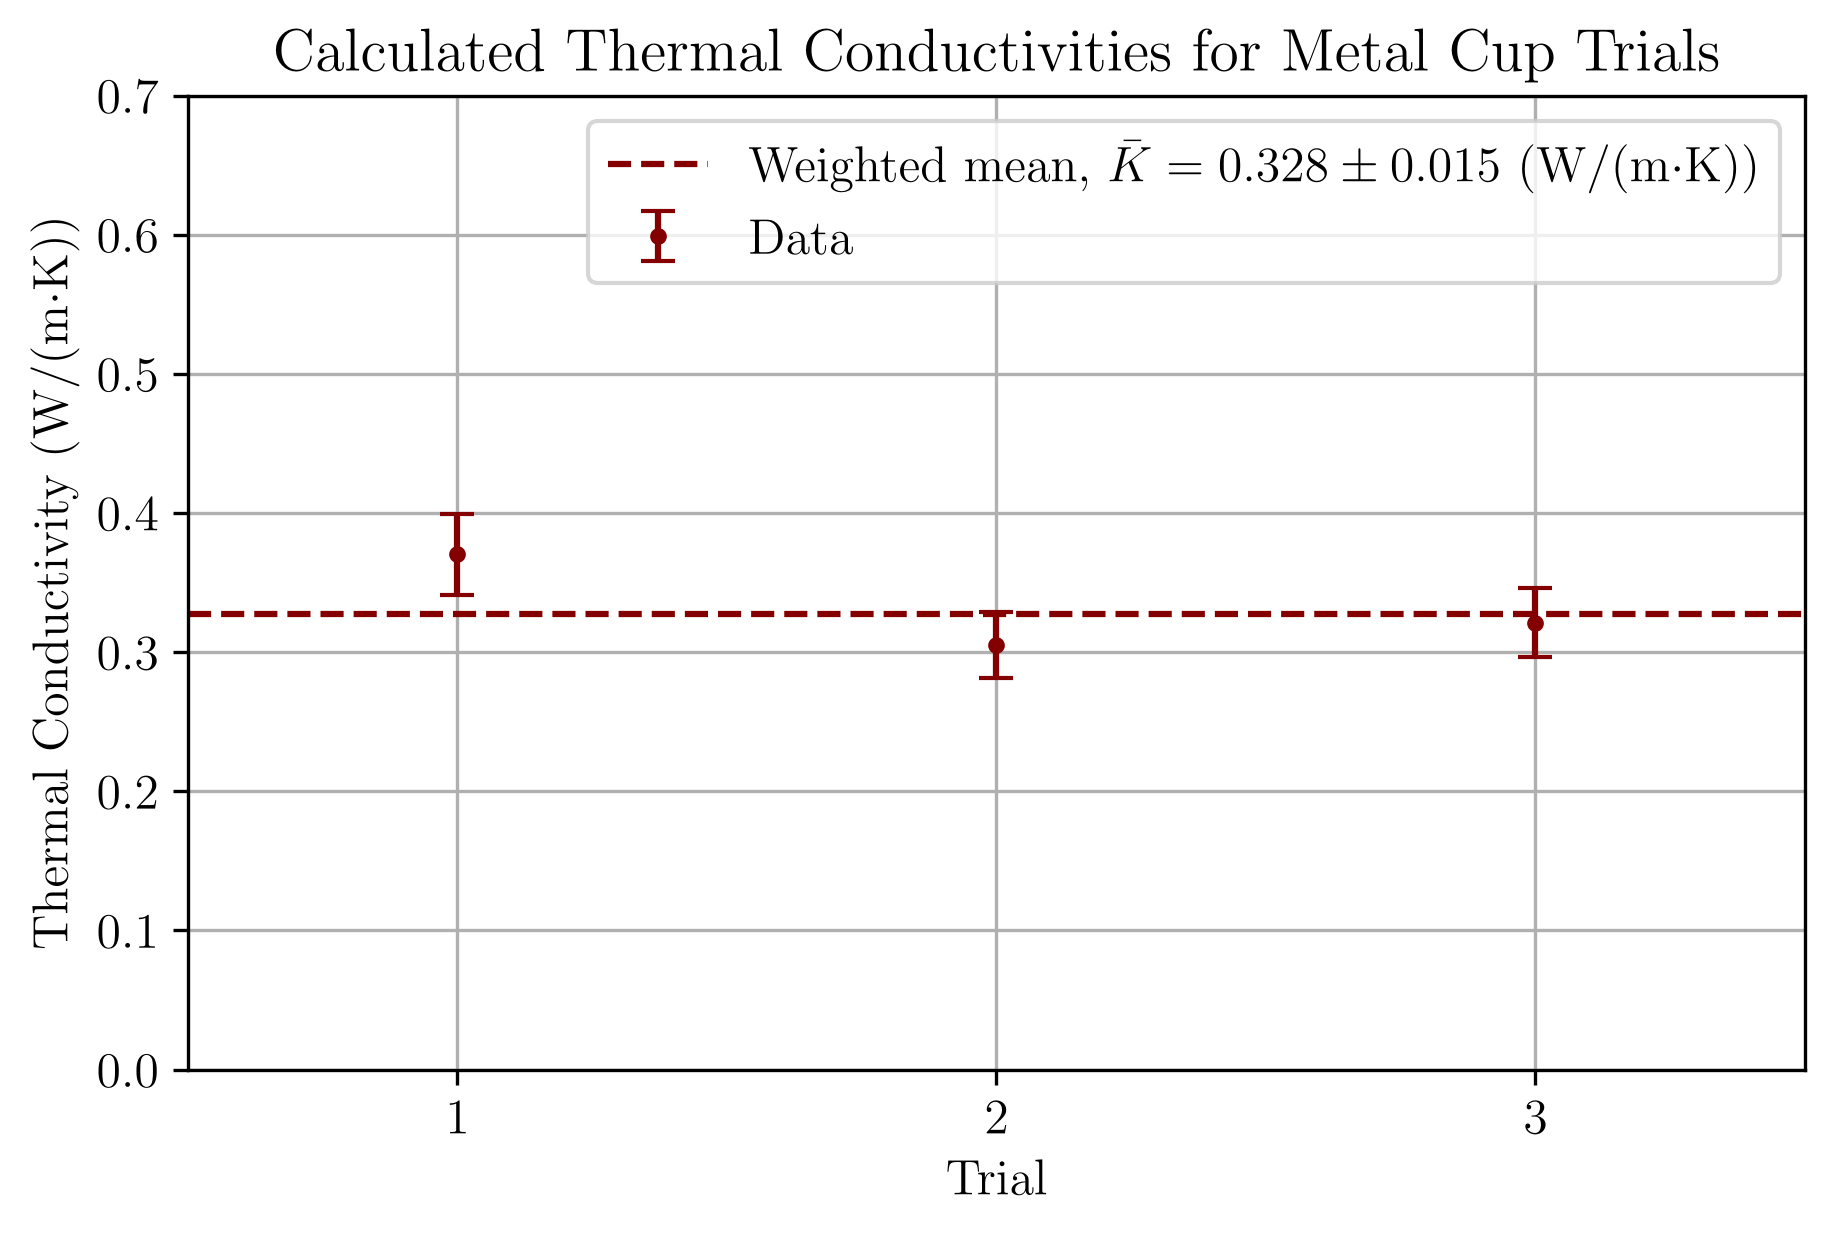

In [172]:
weights = 1 / K_err**2

K_mean = np.sum(weights * K) / np.sum(weights)

K_mean_err = 1 / np.sqrt(np.sum(weights))


print(K_mean, K_mean_err)
print(K)
print(K_err)

K_fig, K_ax = plt.subplots(1, figsize=(6, 4), layout='constrained')

K_ax.errorbar(np.array([1, 2, 3]), K, K_err, fmt = 'o', markersize = 3, capsize = 4, color = 'xkcd:dark red', zorder=10, label = "Data")

K_ax.axhline(K_mean, linestyle='dashed', color = 'xkcd:dark red', label = rf"Weighted mean, $\bar{{K}} = {K_mean:0.3f} \pm {K_mean_err:0.3f}$ (W/(m$\cdot$K))")

K_ax.set_title(rf"Calculated Thermal Conductivities for Metal Cup Trials")

K_ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1))
K_ax.set_xlim(0.5, 3.5)
K_ax.set_ylim(0, 0.7)
K_ax.set_xlabel("Trial")
K_ax.set_ylabel(r"Thermal Conductivity (W/(m$\cdot$K))")

K_ax.legend()

K_fig.savefig("plots/metal_conductivities.png", dpi=400)


